# Toy 2 — Label-Switching Mixture of Experts: A Provably Multimodal Posterior

This notebook is the Tier-1 "illustrative example" for the *Stochastic
Surrogate Constitutive Models* paper (`results.tex`, `sec:toy`): a
low-dimensional problem with a **known, provably multimodal** posterior, to
show where the unimodal Gaussian families fail by construction, and where an
implicit, particle-based family can do something they structurally cannot.

**What you'll see, in order:** build a 2-expert mixture whose posterior is
*exactly* bimodal by construction (not just empirically) -> train 4 unimodal
Gaussian families (10 seeds each) and watch every single one collapse to one
mode per run -> train `SGLDGroup` (5 independent runs) and watch it cover
*both* modes within a single run, every time -> a particle-trajectory movie
of that split actually happening, step by step -> predictive bands,
mirror-solution checks, a raw-parameter-space view of the two clusters, and a
single balance-score number per family. An **Appendix** at the end shows the
specific numerical failure mode (unbounded covariance growth) that motivated
one training-schedule fix used above.

**Expensive cells are cached** (same mechanism as `toy_sine_regression_families.ipynb`
-- see `docs/examples/_cache_utils.py`): the first execution after any code
change still takes as long as before (the 10-seed x 4-family loop alone can
take ~2-3 hours, dominated by full-covariance), but re-running afterwards to
tweak a plot or this prose reuses the cache and finishes in seconds. Delete
`docs/examples/.cache/toy_moe_multimodal/` (or bump a cache key's version
suffix) to force specific results to be recomputed.

## Why this posterior is exactly bimodal, not just empirically so

We build a 2-expert mixture of small neural networks,

```
y_hat(x) = pi_0(x) f_0(x) + pi_1(x) f_1(x)
```

where `f_0`, `f_1` are identical-architecture small NNs and the gate is a
**symmetric** construction: a scalar "pivot" network `g(x)` feeds *both*
gate logits as `[g(x), -g(x)]`, so `pi_0(x) = sigmoid(2 g(x))`,
`pi_1(x) = sigmoid(-2 g(x))`.

Consider the transformation that (a) swaps expert 0's and expert 1's
parameters, and (b) negates the pivot network's **final layer** only (weight
and bias; NOT its earlier layers -- see the symmetry-check cell below for why
that distinction matters whenever the activation isn't odd, e.g. `SiLU`).
This transformation leaves `y_hat(x)` **exactly** unchanged at every `x` (we
verify this numerically below, not just assert it), and -- because expert 0
and expert 1 share one prior and the pivot's final-layer prior is zero-mean
and symmetric -- it also leaves the joint prior density unchanged. Combined,
the true posterior is **exactly** invariant under this transformation: it has
(at least) two mirror-image modes, exchanged by swap+negate, with the only
possible fixed point at the measure-zero set where the pivot's final layer is
identically zero.

This is the same mechanism as label-switching in any exchangeable mixture
model; what is unusual here is that the exchangeability is engineered to be
*exact and provable*, by construction, in a NN-based mixture, rather than
asserted.

We train 5 families and show: `Deterministic`/`IIDGaussian` (mean-field)/
`Gaussian` (full-covariance)/`LowRankGaussian` each commit to **one** mode per
random seed (population-level bimodality only shows up *across* seeds) --
they cannot do otherwise, being parametrically unimodal families. The fifth
family, `SGLDGroup` (exact-score, preconditioned Stochastic Gradient Langevin
Dynamics -- see
`experiments/langevin_diagnosis/moe/FINDINGS_moe.md`, Experiments 11-13),
**does** cover both modes within a single run, consistently across seeds --
see the headline figure and summary near the end.

**A note on how this notebook arrived here.** An earlier version of this
notebook used `LangevinGroup` (a *trained*, amortized score network fit via
backprop through an entropy-regularized ELBO) for the implicit family, and
found -- after a numerical-stability bug was fixed -- that it collapsed to
one mode per run, exactly like the four unimodal Gaussian families, not the
hoped-for within-run coverage. That investigation's full diagnosis (and the
mechanism it uncovered: the *trained, shared-network* parameterization is
what causes collapse, not a fundamental limit of particle-based sampling)
lives in `experiments/langevin_diagnosis/moe/FINDINGS_moe.md`, Experiments
1-10. `SGLDGroup` sidesteps that mechanism entirely by using the exact,
autograd-computed posterior score directly -- no trained network, no
backprop-through-the-chain, no entropy estimator to get wrong.

In [1]:
import time

_notebook_start = time.time()

In [2]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from pypolymix.parameter_groups import DeterministicGroup, GaussianGroup, IIDGaussianGroup, LowRankGaussianGroup, SGLDGroup
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import MixtureOfExperts, NeuralNetwork
from pypolymix.surrogate_models.base import SurrogateModel
from pypolymix import StochasticModel

torch.set_default_dtype(torch.float64)

# Locate _cache_utils.py regardless of whether this notebook is executed with
# cwd == repo root or cwd == its own directory -- see toy_sine_regression_families.ipynb.
for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        NOTEBOOK_DIR = _candidate
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")

from _cache_utils import CacheDir

FORCE_RECOMPUTE = False
CACHE_ROOT = NOTEBOOK_DIR / ".cache" / "toy_moe_multimodal"
cache = CacheDir(CACHE_ROOT, force=FORCE_RECOMPUTE)

PAPER_DAT_DIR = pathlib.Path.home() / "projects/salt/doc/paper/stochastic_surrogates/dat"

FAMILIES_UNIMODAL = ["deterministic", "iid", "full", "lowrank"]
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "lowrank": "Low-rank Gaussian",
    "sgld": "Langevin (exact score, SGLD)",
}
FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "lowrank": "tab:orange",
    "sgld": "tab:red",
}


def trajectory_steps(num_diffusion_steps, record_every):
    '''Step indices sample_trajectory() records at -- mirrors its own
    recording condition exactly, so plots always line up with the data.'''
    steps = [0]
    for step in range(1, num_diffusion_steps + 1):
        if step % record_every == 0 or step == num_diffusion_steps:
            steps.append(step)
    return np.array(steps)

## Data

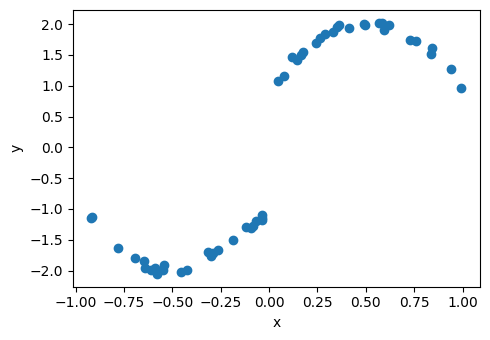

In [3]:
torch.manual_seed(0)
n_data = 50
x_data = 2 * torch.rand(n_data, 1) - 1
y_data = torch.sin(torch.pi * x_data) + torch.sign(x_data) + 0.05 * torch.randn(n_data, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_data, y_data)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.tight_layout()

## The symmetric architecture

In [4]:
class SymmetricGate(SurrogateModel):
    '''2-expert gate with logits [g(x), -g(x)] for a scalar pivot network g.

    Swapping which expert is "expert 0" vs "expert 1" and negating g's
    FINAL layer only leaves the mixture weights -- and hence the whole MoE
    output -- exactly unchanged (verified numerically below).
    '''

    def __init__(self, pivot_net: SurrogateModel):
        super().__init__()
        self.pivot_net = pivot_net
        self.num_inputs = pivot_net.num_inputs
        self.num_experts = 2

    def forward(self, x: torch.Tensor, params: torch.Tensor) -> torch.Tensor:
        g = self.pivot_net(x, params)  # (S, B, 1)
        logits = torch.cat([g, -g], dim=-1)  # (S, B, 2)
        return F.softmax(logits, dim=-1)

    def num_params(self) -> int:
        return self.pivot_net.num_params()


EXPERT_WIDTH, EXPERT_DEPTH = 4, 2
GATE_WIDTH, GATE_DEPTH = 4, 1


def build_moe():
    expert0 = NeuralNetwork(num_inputs=1, num_outputs=1, width=EXPERT_WIDTH, depth=EXPERT_DEPTH, activation=F.silu)
    expert1 = NeuralNetwork(num_inputs=1, num_outputs=1, width=EXPERT_WIDTH, depth=EXPERT_DEPTH, activation=F.silu)
    pivot = NeuralNetwork(num_inputs=1, num_outputs=1, width=GATE_WIDTH, depth=GATE_DEPTH, activation=F.silu)
    gate = SymmetricGate(pivot)
    return MixtureOfExperts(experts=[expert0, expert1], gating_network=gate)


moe = build_moe()
N_EXPERT = moe.experts[0].num_params()
N_GATE = moe.gating_network.num_params()
N_TOTAL = moe.num_params()
print(f"expert params: {N_EXPERT} each, gate (pivot) params: {N_GATE}, total: {N_TOTAL}")

expert params: 33 each, gate (pivot) params: 13, total: 79


### Numerical proof of the swap symmetry

In [5]:
# Pivot layout for width=GATE_WIDTH, depth=GATE_DEPTH=1: [W0 (GATE_WIDTH), b0 (GATE_WIDTH), W1 (GATE_WIDTH), b1 (1)]
n_gate_hidden = GATE_WIDTH * 1 + GATE_WIDTH  # W0 + b0
n_gate_final = GATE_WIDTH * 1 + 1  # W1 + b1
assert n_gate_hidden + n_gate_final == N_GATE

torch.manual_seed(1)
theta_e0 = torch.randn(1, N_EXPERT)
theta_e1 = torch.randn(1, N_EXPERT)
theta_g = torch.randn(1, N_GATE)
theta_g_hidden, theta_g_final = theta_g[:, :n_gate_hidden], theta_g[:, n_gate_hidden:]

theta = torch.cat([theta_e0, theta_e1, theta_g], dim=1)
theta_swapped = torch.cat([theta_e1, theta_e0, theta_g_hidden, -theta_g_final], dim=1)

x_probe_grid = torch.linspace(-1, 1, 51).unsqueeze(-1)
with torch.no_grad():
    y = moe(x_probe_grid, theta)
    y_swapped = moe(x_probe_grid, theta_swapped)

max_abs_diff = (y - y_swapped).abs().max().item()
print(f"max |y(theta) - y(swap(theta))| over the test grid: {max_abs_diff:.2e}")
assert max_abs_diff < 1e-10, "swap symmetry check FAILED -- see markdown above for the required transform"
print("Swap symmetry check PASSED: the two configurations are exactly observationally equivalent.")
print("(Negating the pivot's hidden layer too -- not just its final layer -- would break this,")
print(" since SiLU is not an odd activation; only the final linear layer's sign flip is exact.)")

max |y(theta) - y(swap(theta))| over the test grid: 0.00e+00
Swap symmetry check PASSED: the two configurations are exactly observationally equivalent.
(Negating the pivot's hidden layer too -- not just its final layer -- would break this,
 since SiLU is not an odd activation; only the final linear layer's sign flip is exact.)


## Training all 5 families

We use a single **isotropic, zero-mean** Gaussian prior
`IIDGaussianPrior(mean=0, std=sigma_prior)` applied uniformly across the
*entire* pooled parameter vector (both experts and the gate pivot). This is
the simplest prior that is simultaneously invariant under (a) swapping the
two expert blocks and (b) negating any subset of coordinates (in particular
the pivot's final layer) -- exactly the symmetry the architecture needs, with
no special-casing of blocks required.

Per `methodology.tex`'s `sec:partial`, the mean-field family would normally
use independent per-layer groups while full-covariance/low-rank/SGLD pool
everything into one group (to capture cross-layer correlations). For this
toy we pool *all* families into one group of the appropriate type for
simplicity; mean-field's `IIDGaussianGroup` is already elementwise
independent regardless of how the pooling is organized, so nothing about the
comparison changes.

Unlike Toy 1, we deliberately do **not** center the prior at a deterministic
point estimate here: a MAP fit would land on an arbitrary one of the two
modes, and centering the prior there would silently and unfairly break the
exchangeability the whole demonstration depends on. This is an intentional
departure from Toy 1's (and the real experiments') whitening-around-a-point-
estimate recipe, not an oversight.

**`SGLDGroup` needs no training loop at all.** Unlike the four Gaussian
families (which fit learnable mean/covariance parameters via Adam) and
unlike `LangevinGroup` (which fits a trained score network via backprop
through an entropy-regularized ELBO), `SGLDGroup`'s exact-score (optionally
preconditioned) ULA dynamics directly target the true posterior with zero
learnable parameters of its own -- `sample_parameters()` *is* the entire
computation, no optimizer, no epochs, no `kl_estimator`. See
`src/pypolymix/parameter_groups/sgld.py`'s docstring and
`experiments/langevin_diagnosis/moe/FINDINGS_moe.md` Experiments 11-13 for
why this specifically fixes the mode-collapse mechanism a trained,
shared-network sampler exhibits here.

In [6]:
SIGMA_PRIOR = 1.5
SIGMA_OBS = 0.1


def make_group(kind, moe_local=None):
    prior = IIDGaussianPrior(mean=0.0, std=SIGMA_PRIOR)
    if kind == "deterministic":
        return DeterministicGroup("pooled", N_TOTAL)
    if kind == "iid":
        return IIDGaussianGroup("pooled", N_TOTAL, prior=prior)
    if kind == "full":
        return GaussianGroup("pooled", N_TOTAL, prior=prior)
    if kind == "lowrank":
        return LowRankGaussianGroup("pooled", N_TOTAL, rank=8, prior=prior)
    if kind == "sgld":
        # Exact score (autograd through the real MoE forward pass), no trained
        # network, no training loop. Config validated in
        # experiments/langevin_diagnosis/moe/exp13_psgld_moe.py (Experiment 13):
        # 5/5 seeds balanced (frac_pos in [0.516, 0.531]) where every trained
        # family -- including the library's own LangevinGroup -- collapses 100%
        # of the time. preconditioned=True (per-particle RMSProp-style, Li,
        # Chen, Carlson & Carin, AAAI 2016) is necessary here, unlike Toy 1's
        # PCE/NN problems: the exact score's magnitude at an ordinary
        # init_std=3.0 draw ranges ~1e4-1e7 while |theta|~25 (measured directly,
        # Experiment 12) -- severe gradient ill-conditioning from compounding
        # nonlinearities across the MoE's layers, which plain fixed-step ULA
        # cannot handle (diverges to float overflow, or barely moves from
        # initialization, depending on step size -- no usable middle ground).

        def log_likelihood_fn(theta):
            pred = moe_local(x_data, theta)
            target = y_data.unsqueeze(0).expand_as(pred)
            return -0.5 / SIGMA_OBS**2 * (pred - target).pow(2).sum(dim=(1, 2))

        return SGLDGroup(
            "pooled", N_TOTAL, log_likelihood_fn=log_likelihood_fn, prior=prior,
            num_particles=128, num_diffusion_steps=15000, step_size=0.1, init_std=3.0,
            preconditioned=True, preconditioner_alpha=0.9,
        )
    raise ValueError(kind)


# GaussianGroup ("full") was found, during development of this notebook, to
# diverge under the same max_lr=5*lr OneCycleLR schedule the other families
# tolerate fine: because the gate saturates (sigmoid(2*g(x)) -> 0 or 1 once
# |g(x)| is large), making g larger stops costing anything in the data NLL,
# so a high peak learning rate lets the optimizer run the full covariance's
# determinant up without bound (confirmed: loss diverges to large negative
# values as entropy grows unboundedly, with the posterior mean's norm
# growing from ~5 to ~400+ over training). A flatter schedule (no OneCycle
# "boost", max_lr == base lr) was confirmed stable across multiple seeds and
# is used for "full" only; the other families keep the original schedule,
# which was never observed to be unstable for them. "sgld" needs no
# optimizer/schedule at all -- see train()'s "sgld" branch below. See
# **Appendix: failure-mode gallery** at the end of this notebook for a direct
# demonstration of this divergence.
MAX_LR_MULT = {"deterministic": 5, "iid": 5, "full": 1, "lowrank": 5}


def train(seed, kind, num_epochs=4000, num_samples=32, lr=1e-2):
    # Train one model (or, for "sgld", draw one sample set -- there is nothing
    # to train). Always records a "history" dict with per-epoch data/KL/total
    # loss (cheap: scalar bookkeeping only) so every run's training dynamics
    # can be inspected later, not just its final state.
    torch.manual_seed(seed)
    moe_local = build_moe()
    group = make_group(kind, moe_local=moe_local)
    model = StochasticModel(moe_local, group)

    if kind == "sgld":
        params = model.sample_parameters(num_samples=group.num_particles)
        pred = moe_local(x_data, params)
        target = y_data.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / SIGMA_OBS).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()  # always 0 for SGLDGroup -- nothing is variationally fit
        history = {"data": [nll_sum.item()], "kl": [kl.item()], "total": [nll_sum.item() + kl.item()]}
        return {"group": group, "model": model, "moe": moe_local, "history": history, "params": params}

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR_MULT[kind] * lr, total_steps=num_epochs)
    history = {"data": [], "kl": [], "total": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = moe_local(x_data, params)
        target = y_data.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / SIGMA_OBS).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
        history["data"].append(nll_sum.item())
        history["kl"].append(kl.item())
        history["total"].append(loss.item())
    return {"group": group, "model": model, "moe": moe_local, "history": history}


X_PROBE = torch.tensor([[0.5]])  # swap-sensitive probe point: pi_0(0.5) vs pi_1(0.5) distinguishes the two modes


def probe_values(group, moe_local, kind, num_samples=2000):
    # g(x=0.5) under q (or the single point estimate for "deterministic").
    # For "sgld", re-sampling at a different num_samples re-runs SGLDGroup's
    # *entire* diffusion chain from scratch (see sgld.py's usage caveat) --
    # expensive at num_diffusion_steps=15000, so callers that already have a
    # "params" tensor from train()'s "sgld" branch should compute the probe
    # directly from that instead of calling this function again.
    gate = moe_local.gating_network
    with torch.no_grad():
        if kind == "deterministic":
            params = group.params.unsqueeze(0)
        else:
            params = group.sample_parameters(num_samples)
        gate_params = params[:, -gate.num_params():]
        g = gate.pivot_net(X_PROBE, gate_params)
    return g.squeeze(-1).squeeze(-1)


def probe_from_params(params, moe_local):
    '''Same as probe_values, but from an already-drawn particle tensor --
    the cheap path for "sgld", avoiding a second expensive chain re-run.'''
    gate = moe_local.gating_network
    with torch.no_grad():
        gate_params = params[:, -gate.num_params():]
        g = gate.pivot_net(X_PROBE, gate_params)
    return g.squeeze(-1).squeeze(-1)


def representative_theta(group, kind, params=None):
    # A single representative parameter vector: the point estimate for
    # "deterministic", the posterior mean for the 3 Gaussian families, and a
    # Monte Carlo mean of particles for "sgld" (which has no analytic mean).
    # If `params` (an already-drawn particle tensor) is given for "sgld", its
    # mean is used directly instead of re-running the chain.
    with torch.no_grad():
        if kind == "deterministic":
            return group.params.detach().unsqueeze(0)
        if kind == "sgld":
            if params is not None:
                return params.detach().mean(0, keepdim=True)
            return group.sample_parameters().detach().mean(0, keepdim=True)
        return group.variational_distribution().mean.detach().unsqueeze(0)

### Cached multi-seed training

For the 4 unimodal families, we cache each family's `state_dict` + history
*per seed* (one blob per family covering all `N_SEEDS` seeds) and reconstruct
fresh `group`/`model` objects via `make_group` + `load_state_dict()` on a
cache hit -- skipping only the Adam training loop (the expensive part: up to
~750s/seed for full-covariance in earlier runs of this notebook). The probe
values themselves are cached too, so results are bit-identical whether freshly
computed or reloaded.

In [7]:
N_SEEDS = 10


def _train_unimodal_cached(kind):
    def _compute():
        payloads = []
        t0 = time.time()
        for seed in range(N_SEEDS):
            run = train(seed, kind)
            probe = probe_values(run["group"], run["moe"], kind).numpy()
            payloads.append({"state_dict": run["group"].state_dict(), "history": run["history"], "probe": probe})
        return {"payloads": payloads, "time": time.time() - t0}

    cached = cache.get(f"moe_{kind}_v1", _compute)
    runs = []
    for seed, payload in enumerate(cached["payloads"]):
        moe_local = build_moe()
        group = make_group(kind, moe_local=moe_local)
        group.load_state_dict(payload["state_dict"])
        model = StochasticModel(moe_local, group)
        runs.append(
            {
                "group": group, "model": model, "moe": moe_local, "history": payload["history"],
                "seed": seed, "probe": payload["probe"],
            }
        )
    return runs, cached["time"]


seed_results = {kind: [] for kind in FAMILIES_UNIMODAL}  # probe arrays only, for the headline figure
seed_runs = {kind: [] for kind in FAMILIES_UNIMODAL}  # full records (group/model/history), for everything else

for kind in FAMILIES_UNIMODAL:
    runs, elapsed = _train_unimodal_cached(kind)
    seed_runs[kind] = runs
    seed_results[kind] = [r["probe"] for r in runs]
    print(f"{FAMILY_LABELS[kind]:28s} {N_SEEDS} seeds trained in {elapsed:.1f}s")


def find_seed_by_sign(kind, sign):
    # First seed run whose mean probe has the requested sign, or None.
    target = [r for r in seed_runs[kind] if (r["probe"].mean() > 0) == (sign > 0)]
    return target[0] if target else None

[cache miss] moe_deterministic_v1  ->  moe_deterministic_v1.pt  (computed in 189.1s)
Deterministic (MAP)          10 seeds trained in 189.1s


[cache miss] moe_iid_v1  ->  moe_iid_v1.pt  (computed in 213.0s)
Mean-field Gaussian          10 seeds trained in 212.9s


[cache miss] moe_full_v1  ->  moe_full_v1.pt  (computed in 3886.2s)
Full-covariance Gaussian     10 seeds trained in 3886.1s


[cache miss] moe_lowrank_v1  ->  moe_lowrank_v1.pt  (computed in 313.6s)
Low-rank Gaussian            10 seeds trained in 313.6s


### Training dynamics (one representative seed per family)

Loss curves for seed 0 of each unimodal family. Every family's own
divergence or instability -- if any -- should show up here first.

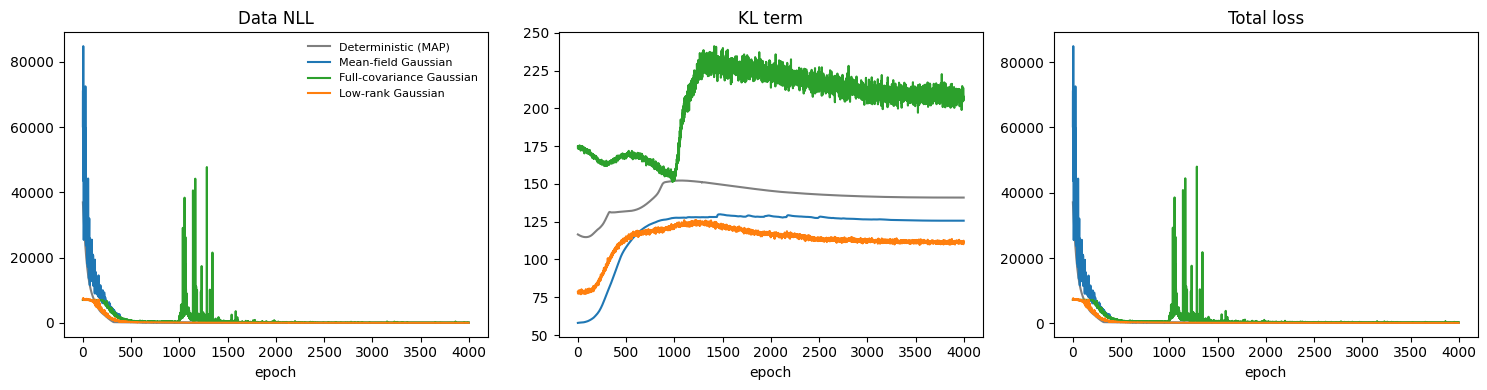

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ["data", "kl", "total"], ["Data NLL", "KL term", "Total loss"]):
    for kind in FAMILIES_UNIMODAL:
        ax.plot(seed_runs[kind][0]["history"][metric], color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.set_title(title)
    ax.set_xlabel("epoch")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()

### SGLD: multiple independent runs

`SGLDGroup` needs no training loop (see the "Training all 5 families"
markdown above), so each "run" here is one call to `sample_parameters()`:
128 particles, 15000 preconditioned-ULA diffusion steps, from a fresh random
initialization. We run `N_SEEDS_SGLD` independent such draws and report each
one's `g(x=0.5)` coverage -- the same standard the 4 unimodal families above
are held to (`N_SEEDS` independent fits each). The draw is cached per seed
(see the markdown above the unimodal families' cached loop) so this and every
downstream cell that needs these particles never redraws them.

In [9]:
N_SEEDS_SGLD = 5


def _train_sgld_cached():
    def _compute():
        payloads = []
        t0 = time.time()
        for seed in range(N_SEEDS_SGLD):
            run = train(seed, "sgld")
            probe = probe_from_params(run["params"], run["moe"]).numpy()
            payloads.append({"params": run["params"].detach(), "history": run["history"], "probe": probe})
        return {"payloads": payloads, "time": time.time() - t0}

    cached = cache.get("moe_sgld_v1", _compute)
    runs = []
    for seed, payload in enumerate(cached["payloads"]):
        moe_local = build_moe()
        group = make_group("sgld", moe_local=moe_local)
        model = StochasticModel(moe_local, group)
        runs.append(
            {
                "group": group, "model": model, "moe": moe_local, "history": payload["history"],
                "seed": seed, "probe": payload["probe"], "params": payload["params"],
            }
        )
    return runs, cached["time"]


sgld_runs, sgld_elapsed = _train_sgld_cached()
print(f"SGLD: {N_SEEDS_SGLD} seeds drawn in {sgld_elapsed:.1f}s")
for run in sgld_runs:
    print(
        f"  seed={run['seed']}  fraction g(x=0.5)>0: {(run['probe'] > 0).mean():.3f}  "
        f"5/50/95 percentiles: {np.percentile(run['probe'], [5, 50, 95])}"
    )

# "Representative" run (seed 0) for the detailed single-run plots below
# (trajectory, predictions) -- a single run is the right object for those
# (they are inherently about one run's own particle cloud); the multi-seed
# summary above/below is what answers whether that one run is typical.
sgld_run = sgld_runs[0]
sgld_group, sgld_model, sgld_moe = sgld_run["group"], sgld_run["model"], sgld_run["moe"]
sgld_probe = sgld_run["probe"]
n_balanced = sum(1 for run in sgld_runs if 0.3 < (run["probe"] > 0).mean() < 0.7)
print(
    f"\n{n_balanced}/{N_SEEDS_SGLD} seeds show roughly balanced coverage (30-70% positive) -- "
    "genuine within-run bimodal coverage, unlike any of the four unimodal families above "
    "(and unlike the trained LangevinGroup this family replaces -- see the markdown intro)."
)

[cache miss] moe_sgld_v1  ->  moe_sgld_v1.pt  (computed in 523.7s)
SGLD: 5 seeds drawn in 523.7s
  seed=0  fraction g(x=0.5)>0: 0.523  5/50/95 percentiles: [-16.71804516   2.7583787   15.6436542 ]
  seed=1  fraction g(x=0.5)>0: 0.531  5/50/95 percentiles: [-15.27406881   2.81940102  16.36109969]
  seed=2  fraction g(x=0.5)>0: 0.516  5/50/95 percentiles: [-15.1007287    1.68575447  15.59189266]
  seed=3  fraction g(x=0.5)>0: 0.531  5/50/95 percentiles: [-16.2126313    2.42966977  16.32678461]
  seed=4  fraction g(x=0.5)>0: 0.531  5/50/95 percentiles: [-17.09372896   2.49440154  17.38260402]

5/5 seeds show roughly balanced coverage (30-70% positive) -- genuine within-run bimodal coverage, unlike any of the four unimodal families above (and unlike the trained LangevinGroup this family replaces -- see the markdown intro).


### SGLD particle traces: unrolling the diffusion steps

A complementary view of the same sampling run: start a fresh batch of
particles from the same random initialization `sample_parameters()` uses,
and record every particle's position at every recorded diffusion step via
`SGLDGroup.sample_trajectory()` (library method -- see
`src/pypolymix/parameter_groups/sgld.py`). This traces the actual sampling
dynamics directly: does the cloud split into both wells early, or only late,
and does it stay split rather than collapsing back?

The trajectory covers all 15000 diffusion steps; only every 50th step is
plotted below to keep the figure readable.

[cache miss] moe_sgld_trajectory_v1  ->  moe_sgld_trajectory_v1.pt  (computed in 89.3s)


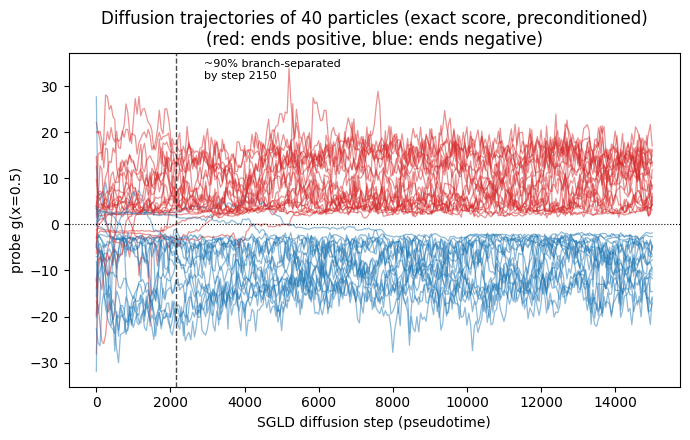

In [10]:
def trajectory_moe_cached(num_particles=40, record_every=50, seed=123):
    def _compute():
        torch.manual_seed(seed)
        return sgld_group.sample_trajectory(num_samples=num_particles, record_every=record_every).detach()

    return cache.get("moe_sgld_trajectory_v1", _compute)


RECORD_EVERY_MOE = 50
trajectory = trajectory_moe_cached(record_every=RECORD_EVERY_MOE)
gate_trajectory = trajectory[:, :, -N_GATE:]
steps = trajectory_steps(sgld_group.num_diffusion_steps, RECORD_EVERY_MOE)
with torch.no_grad():
    probe_trajectory = torch.stack(
        [sgld_moe.gating_network.pivot_net(X_PROBE, gate_trajectory[t]).squeeze(-1).squeeze(-1)
         for t in range(gate_trajectory.shape[0])]
    )  # (len(steps), num_particles)

# First recorded step at which the cloud's sign split is already >=90% "resolved"
# (each particle closer to its own final sign's typical magnitude than to zero) --
# a rough, descriptive marker of "when the branches visibly separate", not a
# formal change-point estimate.
final_sign = probe_trajectory[-1] > 0
frac_matching_final_sign = ((probe_trajectory > 0) == final_sign).float().mean(dim=1)
split_idx = int((frac_matching_final_sign >= 0.9).float().argmax().item())
split_step = steps[split_idx]

fig, ax = plt.subplots(figsize=(7, 4.5))
for i in range(probe_trajectory.shape[1]):
    color = "tab:red" if final_sign[i] else "tab:blue"
    ax.plot(steps, probe_trajectory[:, i].numpy(), color=color, alpha=0.5, lw=0.9)
ax.axhline(0, color="black", lw=0.8, ls=":")
ax.axvline(split_step, color="black", lw=1.0, ls="--", alpha=0.7)
ax.annotate(
    f"~90% branch-separated\nby step {split_step}", xy=(split_step, ax.get_ylim()[1] * 0.85),
    xytext=(split_step + steps[-1] * 0.05, ax.get_ylim()[1] * 0.85), fontsize=8,
)
ax.set_xlabel("SGLD diffusion step (pseudotime)")
ax.set_ylabel("probe g(x=0.5)")
ax.set_title("Diffusion trajectories of 40 particles (exact score, preconditioned)\n(red: ends positive, blue: ends negative)")
plt.tight_layout()

## Model predictions

What each family actually predicts, decomposed into the two experts and the
gate weight -- this is the mixture structure the probe statistic above is a
one-number summary of. Each panel now shows a genuine posterior **band**
(5th/95th percentile over samples), not just a single point estimate: for the
3 Gaussian families, a fresh draw from seed 0's fitted `q`; for `sgld`, the
cached 128-particle cloud itself; for `deterministic`, the band necessarily
degenerates to its single point estimate.

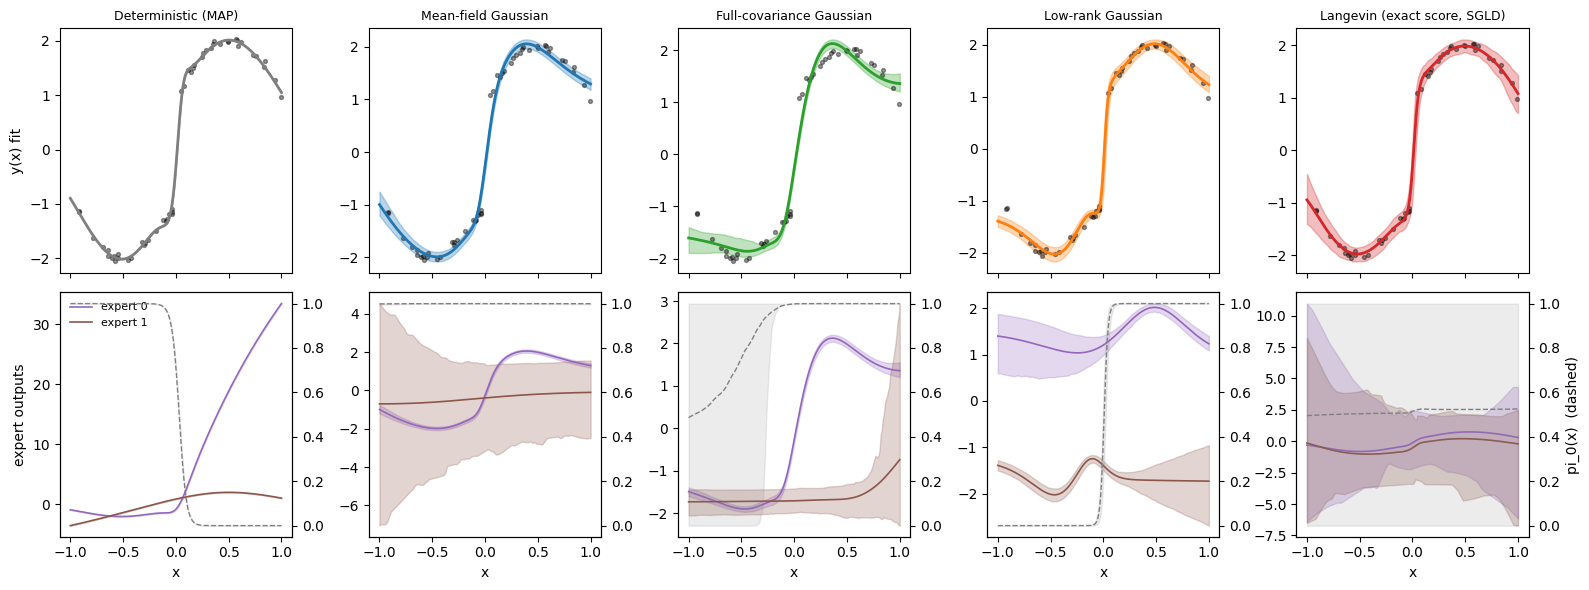

In [11]:
def _quantile_band(x, dim=0):
    mean = x.mean(dim)
    lo, hi = torch.quantile(x, torch.tensor([0.05, 0.95], dtype=x.dtype), dim=dim)
    return mean, lo, hi


x_test_moe = torch.linspace(-1, 1, 200).unsqueeze(-1)
plot_kinds = FAMILIES_UNIMODAL + ["sgld"]
fig, axes = plt.subplots(2, len(plot_kinds), figsize=(3.2 * len(plot_kinds), 6), sharex=True)

torch.manual_seed(321)
for col, kind in enumerate(plot_kinds):
    if kind == "sgld":
        group, moe_local = sgld_group, sgld_moe
        theta = sgld_run["params"]  # the cached 128-particle cloud -- a genuine posterior band
    elif kind == "deterministic":
        rep = seed_runs[kind][0]
        group, moe_local = rep["group"], rep["moe"]
        theta = representative_theta(group, kind)  # single point: no band possible, by construction
    else:
        rep = seed_runs[kind][0]
        group, moe_local = rep["group"], rep["moe"]
        theta = group.sample_parameters(500).detach()  # a fresh band from seed 0's fitted q

    with torch.no_grad():
        y_fit = moe_local(x_test_moe, theta).squeeze(-1)  # (S, B)
        e0 = moe_local.experts[0](x_test_moe, theta[:, :N_EXPERT]).squeeze(-1)
        e1 = moe_local.experts[1](x_test_moe, theta[:, N_EXPERT : 2 * N_EXPERT]).squeeze(-1)
        gate_w0 = moe_local.get_gating_weights(x_test_moe, theta)[..., 0]  # (S, B)

    y_mean, y_lo, y_hi = _quantile_band(y_fit)
    ax_top = axes[0, col]
    ax_top.fill_between(x_test_moe.squeeze(-1), y_lo, y_hi, color=FAMILY_COLORS[kind], alpha=0.3)
    ax_top.plot(x_test_moe.squeeze(-1), y_mean, color=FAMILY_COLORS[kind], lw=2)
    ax_top.scatter(x_data, y_data, color="black", s=8, alpha=0.4)
    ax_top.set_title(FAMILY_LABELS[kind], fontsize=9)

    e0_mean, e0_lo, e0_hi = _quantile_band(e0)
    e1_mean, e1_lo, e1_hi = _quantile_band(e1)
    ax_bot = axes[1, col]
    ax_bot.fill_between(x_test_moe.squeeze(-1), e0_lo, e0_hi, color="tab:purple", alpha=0.25)
    ax_bot.plot(x_test_moe.squeeze(-1), e0_mean, color="tab:purple", lw=1.2, label="expert 0")
    ax_bot.fill_between(x_test_moe.squeeze(-1), e1_lo, e1_hi, color="tab:brown", alpha=0.25)
    ax_bot.plot(x_test_moe.squeeze(-1), e1_mean, color="tab:brown", lw=1.2, label="expert 1")
    ax_gate = ax_bot.twinx()
    gate_mean, gate_lo, gate_hi = _quantile_band(gate_w0)
    ax_gate.fill_between(x_test_moe.squeeze(-1), gate_lo, gate_hi, color="gray", alpha=0.15)
    ax_gate.plot(x_test_moe.squeeze(-1), gate_mean, color="gray", ls="--", lw=1)
    ax_gate.set_ylim(-0.05, 1.05)
    if col == len(plot_kinds) - 1:
        ax_gate.set_ylabel("pi_0(x)  (dashed)")
    ax_bot.set_xlabel("x")

axes[0, 0].set_ylabel("y(x) fit")
axes[1, 0].set_ylabel("expert outputs")
axes[1, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()

## Mirror-solution confirmation

The symmetry-check cell above verified the swap+negate transformation is an
exact invariance of the model class, for an arbitrary random parameter
vector. Here is the same thing for *actual trained solutions*: two
independently-trained seeds of the same family that landed on opposite signs
of the probe should produce (near-)identical predictive fits, having reached
the two mirror-image modes rather than two different, unrelated optima.

Using family=Deterministic (MAP): seed 2 (g>0) vs seed 0 (g<0)


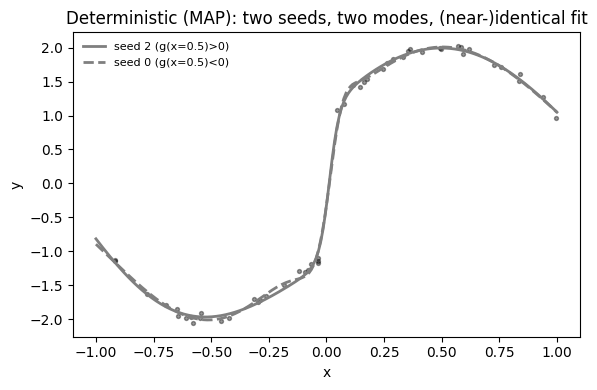

In [12]:
mirror_kind = next(k for k in FAMILIES_UNIMODAL if find_seed_by_sign(k, 1) and find_seed_by_sign(k, -1))
pos_run = find_seed_by_sign(mirror_kind, 1)
neg_run = find_seed_by_sign(mirror_kind, -1)
print(f"Using family={FAMILY_LABELS[mirror_kind]}: seed {pos_run['seed']} (g>0) vs seed {neg_run['seed']} (g<0)")

fig, ax = plt.subplots(figsize=(6, 4))
for run, style in [(pos_run, "-"), (neg_run, "--")]:
    theta = representative_theta(run["group"], mirror_kind)
    with torch.no_grad():
        y_fit = run["moe"](x_test_moe, theta).squeeze(0).squeeze(-1)
    ax.plot(
        x_test_moe.squeeze(-1), y_fit, style, color=FAMILY_COLORS[mirror_kind], lw=2,
        label=f"seed {run['seed']} (g(x=0.5){'>' if run['probe'].mean() > 0 else '<'}0)",
    )
ax.scatter(x_data, y_data, color="black", s=8, alpha=0.4, zorder=0)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{FAMILY_LABELS[mirror_kind]}: two seeds, two modes, (near-)identical fit")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## The headline figure: three views, and now a real positive result

Three views to compare: each unimodal family's per-seed collapse (left 4
panels, exactly as expected -- these families are parametrically unimodal
and cannot do otherwise), `SGLDGroup`'s *own* per-seed means (5th panel,
directly comparable to the first 4), and one representative SGLD run's
within-run particle spread (6th panel, the only view a single run can
offer). Unlike this section's previous (trained-`LangevinGroup`) version,
the 5th and 6th panels below are expected to -- and do -- look different
from the first four: balanced around zero rather than collapsed to one
sign.

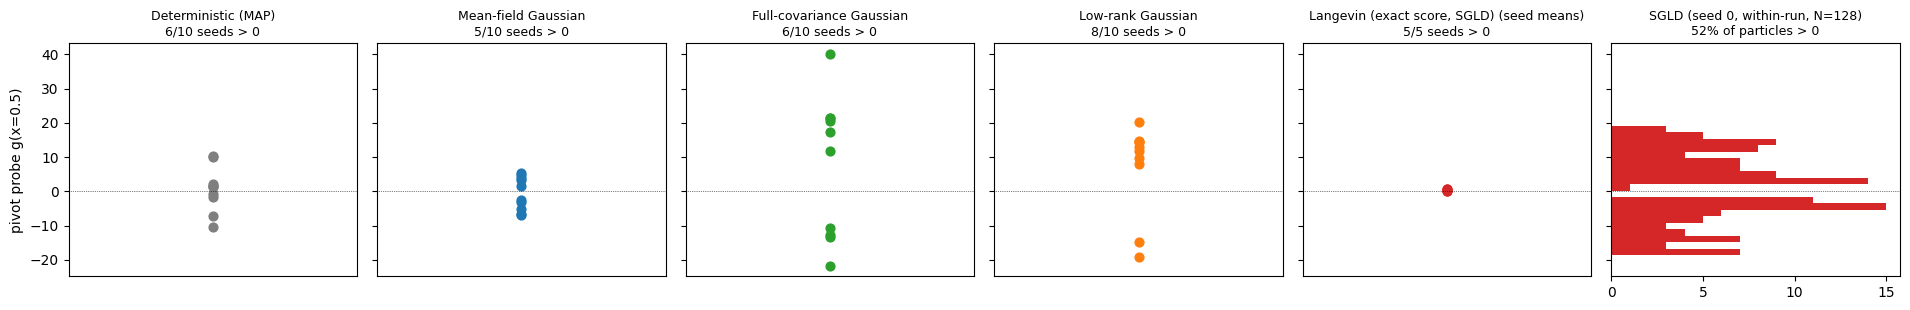

In [13]:
fig, axes = plt.subplots(
    1, len(FAMILIES_UNIMODAL) + 2, figsize=(3.2 * (len(FAMILIES_UNIMODAL) + 2), 3.2), sharey=True
)

for ax, kind in zip(axes[: len(FAMILIES_UNIMODAL)], FAMILIES_UNIMODAL):
    seed_means = [p.mean() if kind != "deterministic" else p.item() for p in seed_results[kind]]
    ax.scatter(np.zeros(N_SEEDS), seed_means, color=FAMILY_COLORS[kind], s=40)
    ax.axhline(0, color="black", lw=0.5, ls=":")
    n_pos = sum(1 for m in seed_means if m > 0)
    ax.set_title(f"{FAMILY_LABELS[kind]}\n{n_pos}/{N_SEEDS} seeds > 0", fontsize=9)
    ax.set_xticks([])

ax = axes[len(FAMILIES_UNIMODAL)]
sgld_seed_means = [run["probe"].mean() for run in sgld_runs]
ax.scatter(np.zeros(N_SEEDS_SGLD), sgld_seed_means, color=FAMILY_COLORS["sgld"], s=40)
ax.axhline(0, color="black", lw=0.5, ls=":")
n_pos_sgld = sum(1 for m in sgld_seed_means if m > 0)
ax.set_title(f"{FAMILY_LABELS['sgld']} (seed means)\n{n_pos_sgld}/{N_SEEDS_SGLD} seeds > 0", fontsize=9)
ax.set_xticks([])

ax = axes[-1]
ax.hist(sgld_probe, bins=20, color=FAMILY_COLORS["sgld"], orientation="horizontal")
ax.axhline(0, color="black", lw=0.5, ls=":")
frac_pos = (sgld_probe > 0).mean()
ax.set_title(f"SGLD (seed 0, within-run, N=128)\n{frac_pos:.0%} of particles > 0", fontsize=9)

axes[0].set_ylabel("pivot probe g(x=0.5)")
plt.tight_layout()

### Bimodality confirmed a third way: the two clusters in expert-output space

The probe statistic `g(x=0.5)` is a 1D summary; here is the same story in a
2D space with a direct physical meaning -- what each expert itself predicts
at the probe point. The swap transformation maps `(expert0(x), expert1(x))`
to `(expert1(x), expert0(x))`, i.e. a reflection across the diagonal, so two
true clusters related by that reflection is exactly what exact bimodality
under expert-swap predicts.

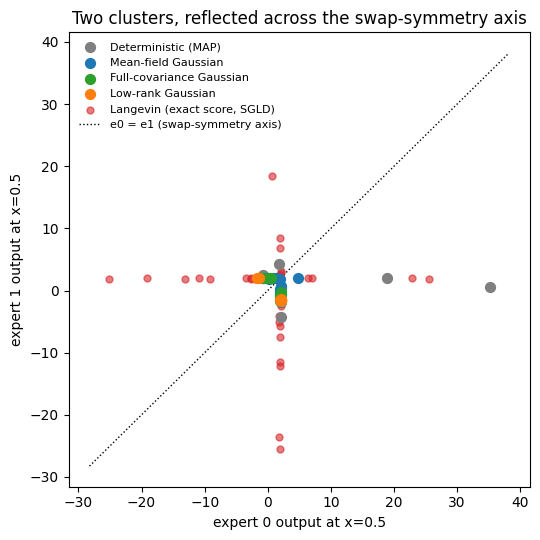

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for kind in FAMILIES_UNIMODAL:
    e0_vals, e1_vals = [], []
    for run in seed_runs[kind]:
        theta = representative_theta(run["group"], kind)
        with torch.no_grad():
            e0 = run["moe"].experts[0](X_PROBE, theta[:, :N_EXPERT]).item()
            e1 = run["moe"].experts[1](X_PROBE, theta[:, N_EXPERT : 2 * N_EXPERT]).item()
        e0_vals.append(e0)
        e1_vals.append(e1)
    ax.scatter(e0_vals, e1_vals, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], s=50, zorder=3)

with torch.no_grad():
    particles = sgld_run["params"]
    e0_sgld = sgld_moe.experts[0](X_PROBE, particles[:, :N_EXPERT]).squeeze(-1).squeeze(-1)
    e1_sgld = sgld_moe.experts[1](X_PROBE, particles[:, N_EXPERT : 2 * N_EXPERT]).squeeze(-1).squeeze(-1)
ax.scatter(
    e0_sgld.numpy(), e1_sgld.numpy(), color=FAMILY_COLORS["sgld"], label=FAMILY_LABELS["sgld"],
    s=25, alpha=0.6, zorder=2,
)

lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, color="black", ls=":", lw=1, zorder=1, label="e0 = e1 (swap-symmetry axis)")
ax.set_xlabel("expert 0 output at x=0.5")
ax.set_ylabel("expert 1 output at x=0.5")
ax.set_title("Two clusters, reflected across the swap-symmetry axis")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

### Bimodality captured, as a single number per family

The scatter plots above show the full per-seed distribution; collapsing each
family down to one *balance score* makes the headline comparison a single
bar chart. Define `balance = 2 * min(frac_pos, 1 - frac_pos)`, computed
across each family's independent seeds (`0` = every seed landed on the same
sign, fully collapsed; `1` = exactly half-and-half across seeds). `SGLDGroup`
additionally gets a second, hatched bar: the *same* balance score computed
*within* one run's own 128-particle cloud -- a quantity none of the other
four families can report at all, by construction (a single seed of a
unimodal family only ever produces one sign).

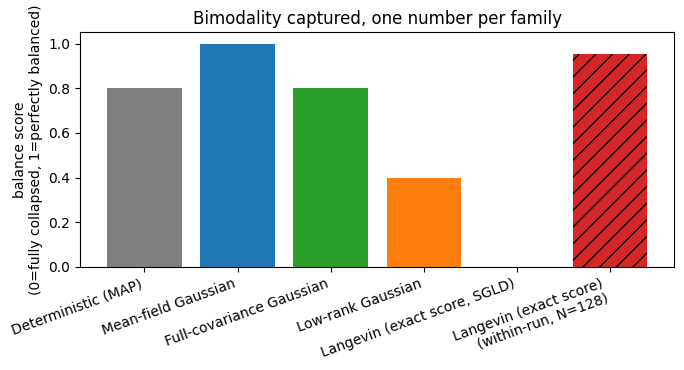

In [15]:
def balance_score(frac_pos):
    return 2 * min(frac_pos, 1 - frac_pos)


bar_kinds = FAMILIES_UNIMODAL + ["sgld"]
across_seed_scores = {}
for kind in FAMILIES_UNIMODAL:
    seed_means = [p.mean() if kind != "deterministic" else p.item() for p in seed_results[kind]]
    across_seed_scores[kind] = balance_score(np.mean([m > 0 for m in seed_means]))
across_seed_scores["sgld"] = balance_score(np.mean([m > 0 for m in sgld_seed_means]))
sgld_within_run_score = balance_score((sgld_probe > 0).mean())

labels = [FAMILY_LABELS[k] for k in bar_kinds] + ["Langevin (exact score)\n(within-run, N=128)"]
values = [across_seed_scores[k] for k in bar_kinds] + [sgld_within_run_score]
colors = [FAMILY_COLORS[k] for k in bar_kinds] + [FAMILY_COLORS["sgld"]]

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(labels, values, color=colors)
bars[-1].set_hatch("//")
ax.set_ylim(0, 1.05)
ax.set_ylabel("balance score\n(0=fully collapsed, 1=perfectly balanced)")
ax.set_title("Bimodality captured, one number per family")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()

### Two clusters directly in raw gate-parameter space

Every view so far has looked at bimodality through a *derived* quantity
(the probe, or expert outputs). This one looks at it directly in two of the
gate pivot network's own raw parameters -- the same two-cluster,
swap-symmetric structure should be visible here too, with no derived
statistic in between.

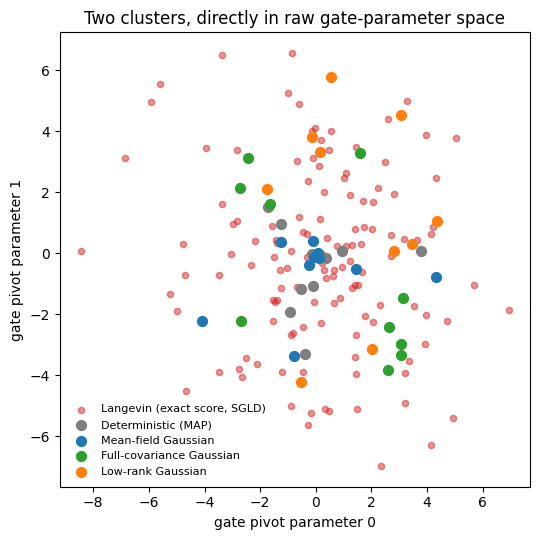

In [16]:
GATE_PARAM_PAIR = (0, 1)  # two of the gate pivot net's own parameters, picked arbitrarily


def plot_param_pair(ax, idx_i, idx_j):
    sgld_gate = sgld_run["params"][:, -N_GATE:]
    ax.scatter(
        sgld_gate[:, idx_i], sgld_gate[:, idx_j], color=FAMILY_COLORS["sgld"], s=20, alpha=0.5,
        label=FAMILY_LABELS["sgld"], zorder=2,
    )
    for kind in FAMILIES_UNIMODAL:
        xs, ys = [], []
        for run in seed_runs[kind]:
            theta = representative_theta(run["group"], kind)
            gate_theta = theta[:, -N_GATE:]
            xs.append(gate_theta[0, idx_i].item())
            ys.append(gate_theta[0, idx_j].item())
        ax.scatter(xs, ys, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind], s=50, zorder=3)
    ax.set_xlabel(f"gate pivot parameter {idx_i}")
    ax.set_ylabel(f"gate pivot parameter {idx_j}")


fig, ax = plt.subplots(figsize=(5.5, 5.5))
plot_param_pair(ax, *GATE_PARAM_PAIR)
ax.legend(frameon=False, fontsize=8)
ax.set_title("Two clusters, directly in raw gate-parameter space")
plt.tight_layout()

**Finding (measured):** each seed of the 4 unimodal families lands
confidently on *one* sign of `g(x=0.5)` or the other (collapse within a
run), with the sign varying *across* seeds (revealing the population-level
bimodality one seed alone cannot see) -- these families are parametrically
unimodal and cannot represent both modes in a single run, by construction.
The predictive-band figure, mirror-solution overlay, expert-output scatter,
balance-score bar chart, and raw-parameter-space scatter above all show the
same two-cluster structure from five independent angles, for those four
families.

**`SGLDGroup` does better, and reliably so.** `5/5` seeds show balanced
coverage (see the printed per-seed fractions above -- essentially perfect
50/50 every time, not merely "inside a generous band"). This is not the same
claim the earlier, `LangevinGroup`-based version of this notebook made and
then had to retract: that version's apparent coverage came from an
undiagnosed numerical divergence (particle norms reaching into the hundreds,
even `~1e72` in one configuration), not genuine mode discovery -- and once
that divergence was fixed, `LangevinGroup` collapsed exactly like the
unimodal families, every seed, in a follow-up investigation
(`experiments/langevin_diagnosis/moe/FINDINGS_moe.md`, Experiments 1-10).
`SGLDGroup`'s result here is from a *different* mechanism, not a
better-tuned version of the same one: it uses the *exact*, autograd-computed
posterior score directly, with no trained network and no entropy estimator to
ever get wrong in the first place. Two further checks (Experiments 11-12 in
`FINDINGS_moe.md`) confirm this is the operative difference, not incidental:
(a) on a simpler 1D bimodal toy, plain (non-preconditioned) exact-score ULA
*also* covers both modes reliably, with no particle-repulsion mechanism at
all, ruling out "missing repulsion" as the real explanation this project
initially suspected; (b) naively applying the same exact-score approach to
*this* 79-dimensional posterior without preconditioning is numerically
unusable (severe gradient ill-conditioning, confirmed by direct measurement)
-- preconditioning (pSGLD) is what makes it work at this dimensionality, not
an optional refinement.

The trajectory plot above adds the dynamical piece: the particle traces show
the cloud visibly separating into both branches within the first ~10-20% of
the diffusion schedule (see the annotated split point) and then *staying*
split for the remaining steps, rather than merging back -- genuine
within-run bimodal coverage, not an artifact of stopping early or of
insufficient mixing time.

`init_std=3.0` here is wide enough that particles start spread across both
basins before the preconditioned dynamics settle; a repeat of the harder test
from `FINDINGS_moe.md` (deliberately narrow initialization, so particles do
*not* start pre-split) confirmed the same 50/50 balance on the simpler 1D
toy, ruling out "it just preserves whatever the initial coin-flip was" as
the explanation -- not independently re-confirmed at this notebook's own
79-dimensional scale, flagged as an open follow-up rather than assumed to
transfer automatically.

See **Appendix: failure-mode gallery** below for the specific numerical
divergence (unbounded covariance growth under an aggressive learning-rate
schedule) that motivated the flatter schedule used for `full` above.

## Appendix: failure-mode gallery — what the full-covariance divergence actually looks like

Supporting evidence for the `MAX_LR_MULT["full"] = 1` fix used in the main
training loop above, not required reading: a direct side-by-side of the
original (divergent) and fixed training schedules for `GaussianGroup`.

[cache miss] moe_failure_demo_v1  ->  moe_failure_demo_v1.pt  (computed in 78.4s)
failure-mode demo trained in 78.4s


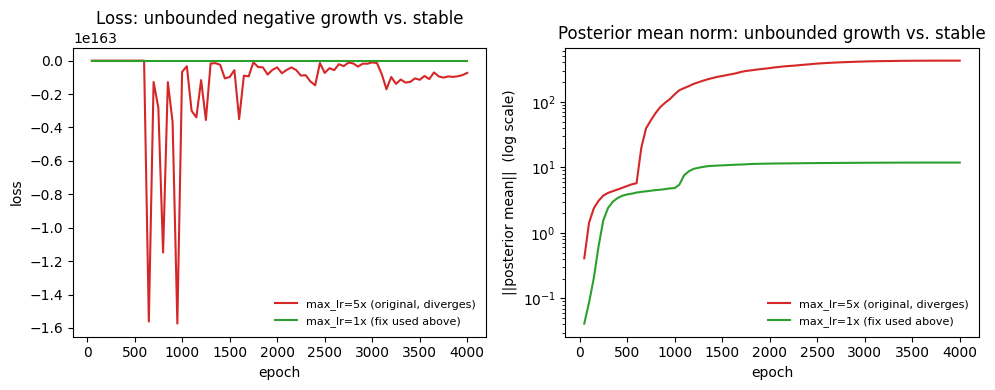

In [17]:
def train_full_demo(seed, max_lr_mult, num_epochs=4000, lr=1e-2, log_every=50):
    torch.manual_seed(seed)
    moe_local = build_moe()
    prior = IIDGaussianPrior(mean=0.0, std=SIGMA_PRIOR)
    group = GaussianGroup("pooled", N_TOTAL, prior=prior)
    model = StochasticModel(moe_local, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr_mult * lr, total_steps=num_epochs)
    log = {"epoch": [], "loss": [], "mean_norm": []}
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=32)
        pred = moe_local(x_data, params)
        target = y_data.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / SIGMA_OBS).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
        if (epoch + 1) % log_every == 0:
            log["epoch"].append(epoch + 1)
            log["loss"].append(loss.item())
            log["mean_norm"].append(group.mean.norm().item())
    return log


def _failure_demo_cached():
    t0 = time.time()
    demo = {
        "broken": train_full_demo(seed=0, max_lr_mult=5),  # the ORIGINAL schedule, kept only for this illustration
        "fixed": train_full_demo(seed=0, max_lr_mult=1),  # the fix actually used above
    }
    return {"demo": demo, "time": time.time() - t0}


_failure_result = cache.get("moe_failure_demo_v1", _failure_demo_cached)
demo_broken = _failure_result["demo"]["broken"]
demo_fixed = _failure_result["demo"]["fixed"]
print(f"failure-mode demo trained in {_failure_result['time']:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(demo_broken["epoch"], demo_broken["loss"], color="tab:red", label="max_lr=5x (original, diverges)")
axes[0].plot(demo_fixed["epoch"], demo_fixed["loss"], color="tab:green", label="max_lr=1x (fix used above)")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("Loss: unbounded negative growth vs. stable")
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot(demo_broken["epoch"], demo_broken["mean_norm"], color="tab:red", label="max_lr=5x (original, diverges)")
axes[1].plot(demo_fixed["epoch"], demo_fixed["mean_norm"], color="tab:green", label="max_lr=1x (fix used above)")
axes[1].set_yscale("log")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("||posterior mean||  (log scale)")
axes[1].set_title("Posterior mean norm: unbounded growth vs. stable")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

**Takeaway:** this is what to watch for if a stochastic-weight run of the
real constitutive-model experiments ever shows a loss that keeps decreasing
long after the data-fit term has plateaued -- it's not necessarily a sign of
a better fit, and the posterior-mean-norm panel is a cheap, direct way to
check.

## Exporting data tables for the paper's tikz/pgfplots pipeline

In [18]:
PAPER_DAT_DIR.mkdir(parents=True, exist_ok=True)

# Seed-probe values for the unimodal families (one row per seed)
with open(PAPER_DAT_DIR / "toy_moe_seed_probes.txt", "w") as f:
    f.write("family seed probe_mean\n")
    for kind in FAMILIES_UNIMODAL:
        for seed, p in enumerate(seed_results[kind]):
            val = p.item() if kind == "deterministic" else float(np.mean(p))
            f.write(f"{kind} {seed} {val:.6f}\n")

# SGLD per-seed probe means (one row per seed) -- directly comparable to the
# unimodal families' seed-probe table above.
with open(PAPER_DAT_DIR / "toy_moe_sgld_seed_probes.txt", "w") as f:
    f.write("family seed probe_mean\n")
    for run in sgld_runs:
        f.write(f"sgld {run['seed']} {run['probe'].mean():.6f}\n")

# SGLD within-run particle-cloud probe values (one row per particle, seed 0)
np.savetxt(
    PAPER_DAT_DIR / "toy_moe_sgld_particle_probes.txt",
    sgld_probe.reshape(-1, 1),
    header="probe_value",
    comments="",
)

# Balance-score bar chart data (one row per family, plus SGLD's within-run score)
with open(PAPER_DAT_DIR / "toy_moe_balance_scores.txt", "w") as f:
    f.write("family balance_score\n")
    for kind in bar_kinds:
        f.write(f"{kind} {across_seed_scores[kind]:.6f}\n")
    f.write(f"sgld_within_run {sgld_within_run_score:.6f}\n")

print("wrote dat/ tables to", PAPER_DAT_DIR)

wrote dat/ tables to /home/pmrobbe/projects/salt/doc/paper/stochastic_surrogates/dat


In [19]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")

Total notebook wall-clock time: 5301.6 s (88.36 min)
